In [27]:
#Import librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math 
from scipy.stats import pearsonr
import scipy.stats as stats
from plotly.subplots import make_subplots
from scipy.stats import shapiro
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore") 
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
import plotly.graph_objects as go
import plotly.express as px
import missingno as msno
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import skew, shapiro
from scipy.stats import boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
import itertools
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import shap
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from collections import Counter
from sklearn.feature_selection import SelectKBest
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from prettytable import PrettyTable
import featuretools as ft
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import lightgbm as lgb

In [28]:
#import data
data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data_cleaned+scaled.csv',encoding='ISO-8859-1')

In [29]:
# aggregate numeric features per customer
customer_features = data.groupby('CustomerID').agg(
    TotalPurchases=('TotalPrice','sum'),
    AvgPurchaseValue=('TotalPrice','mean'),
    AvgSentiment=('SentimentScore','mean'),
    NumDeluxeProducts=('IsDeluxe','sum'),
    NumClustersPurchased=('ProductClusterSemantic','nunique'),
    DaysSinceFirstPurchase=('DaysSinceFirstPurchase','max')
).reset_index()


print(customer_features.head())


   CustomerID  TotalPurchases  AvgPurchaseValue  AvgSentiment  \
0    0.000000        0.698533          0.349267      0.722222   
1    0.000168       72.074800          0.396015      0.448499   
2    0.000337       11.933567          0.384954      0.436081   
3    0.000505       28.180500          0.386034      0.475420   
4    0.000673        6.531333          0.384196      0.450980   

   NumDeluxeProducts  NumClustersPurchased  DaysSinceFirstPurchase  
0                0.0                     1                0.000000  
1                2.0                     5                0.978552  
2                0.0                     3                0.756032  
3                2.0                     5                0.000000  
4                0.0                     5                0.000000  


In [30]:
# target = total revenue per customer
customer_features['CLV'] = customer_features['TotalPurchases']


In [31]:
# split data

X = customer_features.drop(columns=['CustomerID','CLV'])
y = customer_features['CLV']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)


Training set: (3497, 6)
Test set: (875, 6)


In [32]:
import optuna
import lightgbm as lgb
from lightgbm import early_stopping, log_evaluation
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def objective(trial):
    params = {
        'objective': 'regression',
        'metric': 'rmse',
        'boosting_type': 'gbdt',
        'verbosity': -1,
        'seed': 42,
        # refined ranges for better generalization
        'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.07, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 100, 180),
        'max_depth': trial.suggest_int('max_depth', 8, 12),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 50),
        'feature_fraction': trial.suggest_float('feature_fraction', 0.6, 0.8),
        'bagging_fraction': trial.suggest_float('bagging_fraction', 0.8, 0.9),
        'bagging_freq': trial.suggest_int('bagging_freq', 5, 10),
        'lambda_l1': trial.suggest_float('lambda_l1', 4.0, 6.0),
        'lambda_l2': trial.suggest_float('lambda_l2', 3.5, 6.0),
        'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0.7, 1.0),
    }


    train_data = lgb.Dataset(X_train, label=y_train)
    test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)


    gbm = lgb.train(
        params,
        train_data,
        valid_sets=[test_data],
        callbacks=[
            early_stopping(stopping_rounds=150),  
            log_evaluation(period=0)
        ]
    )

    
    y_pred = gbm.predict(X_test, num_iteration=gbm.best_iteration)
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    return rmse


study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100, show_progress_bar=True)

# best params
print("✅ Best trial:")
print(f"  RMSE: {study.best_trial.value:.4f}")
for key, value in study.best_trial.params.items():
    print(f"    {key}: {value}")


best_params = study.best_trial.params
best_params.update({
    'objective': 'regression',
    'metric': 'rmse',
    'boosting_type': 'gbdt',
    'verbosity': -1,
    'seed': 42
})

train_data = lgb.Dataset(X_train, label=y_train)
test_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

model = lgb.train(
    best_params,
    train_data,
    valid_sets=[test_data],
    callbacks=[
        early_stopping(stopping_rounds=150),
        log_evaluation(period=50)
    ]
)


y_pred = model.predict(X_test, num_iteration=model.best_iteration)
rmse = mean_squared_error(y_test, y_pred, squared=False)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nFinal model performance:")
print(f"RMSE: {rmse:.2f}, MAE: {mae:.2f}, R²: {r2:.2f}")


[I 2025-10-14 11:22:57,367] A new study created in memory with name: no-name-70de35db-cfbe-4325-a766-bc9ecf3c0344


  0%|          | 0/100 [00:00<?, ?it/s]

Training until validation scores don't improve for 150 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's rmse: 82.1151
[I 2025-10-14 11:22:57,458] Trial 0 finished with value: 82.11505978681961 and parameters: {'learning_rate': 0.05444256461066991, 'num_leaves': 153, 'max_depth': 9, 'min_data_in_leaf': 33, 'feature_fraction': 0.695098406053025, 'bagging_fraction': 0.8432821620156362, 'bagging_freq': 7, 'lambda_l1': 5.521541469448722, 'lambda_l2': 4.150956666155404, 'min_gain_to_split': 0.9697385294832819}. Best is trial 0 with value: 82.11505978681961.
Training until validation scores don't improve for 150 rounds
Did not meet early stopping. Best iteration is:
[100]	valid_0's rmse: 79.4238
[I 2025-10-14 11:22:57,531] Trial 1 finished with value: 79.42377101170969 and parameters: {'learning_rate': 0.06026705174361538, 'num_leaves': 115, 'max_depth': 9, 'min_data_in_leaf': 24, 'feature_fraction': 0.7918314953865458, 'bagging_fraction': 0.8218770821180283, 'bagging_fr

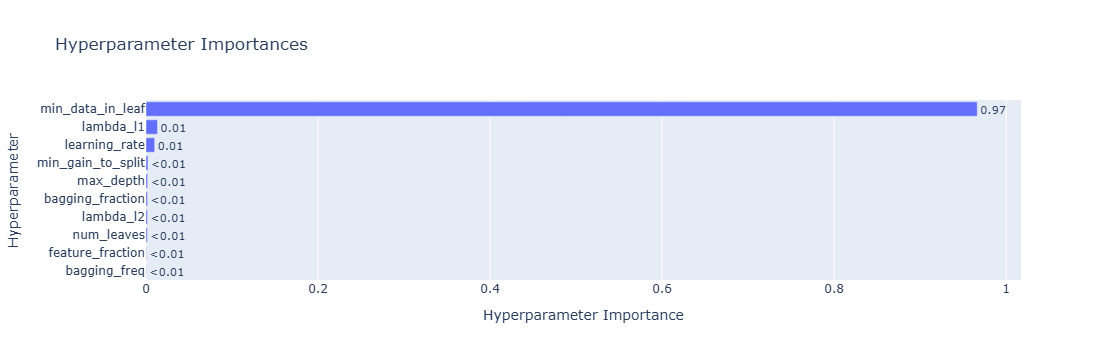

In [33]:
optuna.visualization.plot_optimization_history(study)
optuna.visualization.plot_param_importances(study)


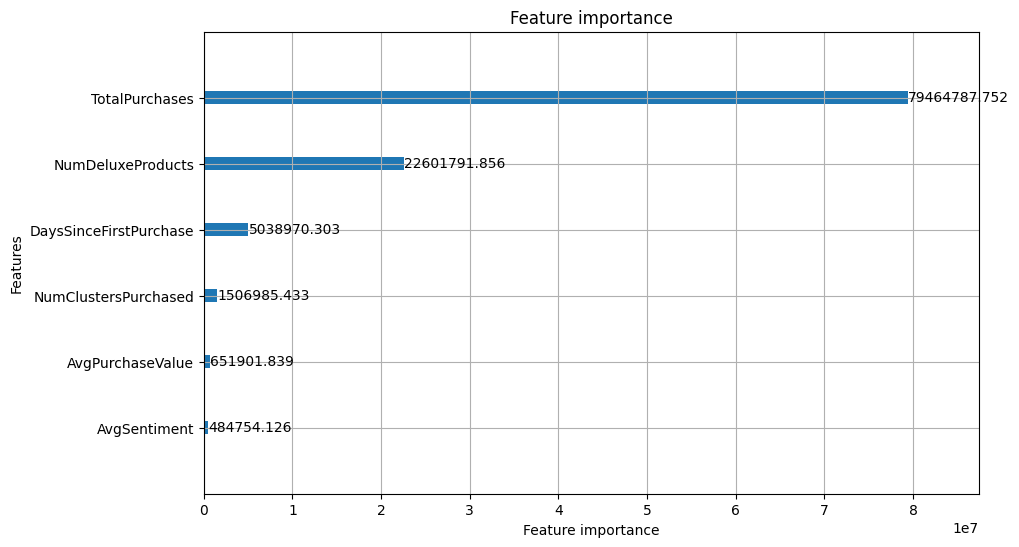

In [34]:
lgb.plot_importance(model, max_num_features=20, importance_type='gain', figsize=(10,6))
plt.show()
